# 01 · Análise de `results/ideal.csv`

Mapas de calor **porta × entrada** por **família** e **base**, e tabela de **k95**.

**Convenções (conferidas nos dados na célula de sanidade):**

- `entrada = zeros` → estado de entrada |0…0⟩ (colunas `*_base*` sem sufixo `_x`: `tvd_base_media`, `p_revela_base`, `k95_base`).
- `entrada = mais` → estado de entrada |+…+⟩ (colunas com sufixo `_x`: `tvd_base_x_media`, `p_revela_base_x`, `k95_base_x`).
- `p_revela` = fração das inserções (posição × papel × qubit) em que a porta é revelada pela distribuição de saída.
- `k95` = menor número `k` de inserções independentes tal que `1 − (1 − p)^k ≥ 0,95`; `∞` quando `p = 0`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

CSV = Path("../results/ideal.csv")

FAMILIAS = ["reversivel", "oraculo", "emaranhamento"]
BASES = ["z", "x"]
PORTAS = ["x", "z", "h", "t", "rz_pi16"]
ENTRADAS = ["zeros", "mais"]
ROTULO_ENTRADA = {"zeros": "|0…0⟩", "mais": "|+…+⟩"}
ALVO = 0.95

df = pd.read_csv(CSV)
print(df.shape)
df.head()

(220, 20)


,familia,circuito,n_qubits,base,porta,posicao,papel,qubit,camada,n_camadas,tvd_zeros,revela_zeros,tvd_mais,revela_mais,tvd_base_media,p_revela_base,k95_base,tvd_base_x_media,p_revela_base_x,k95_base_x
0,reversivel,somador_completo,4,z,x,inicio,ativo,3,0,4,1.0,True,0.0,False,1.0,1.0,1.0,0.0,0.0,inf
1,reversivel,somador_completo,4,z,x,inicio,ocioso,2,0,4,1.0,True,0.0,False,1.0,1.0,1.0,0.0,0.0,inf
2,reversivel,somador_completo,4,z,x,meio,ativo,3,2,4,1.0,True,0.0,False,1.0,1.0,1.0,0.0,0.0,inf
3,reversivel,somador_completo,4,z,x,meio,ocioso,0,2,4,1.0,True,0.0,False,1.0,1.0,1.0,0.0,0.0,inf
4,reversivel,somador_completo,4,z,x,fim,ativo,2,3,4,1.0,True,0.0,False,1.0,1.0,1.0,0.0,0.0,inf


## Formato longo (uma linha por inserção × entrada)

In [2]:
longo = pd.concat([
    df.assign(entrada="zeros", p_revela=df["p_revela_base"],   tvd=df["tvd_base_media"]),
    df.assign(entrada="mais",  p_revela=df["p_revela_base_x"], tvd=df["tvd_base_x_media"]),
], ignore_index=True)[
    ["familia", "circuito", "base", "porta", "posicao", "papel", "qubit",
     "entrada", "p_revela", "tvd"]
]

# Sanidade: mapeamento das colunas e k95 do CSV vs. fórmula.
def k95(p, alvo=ALVO):
    p = np.asarray(p, dtype=float)
    k = np.full(p.shape, np.inf)
    k[p >= 1] = 1
    m = (p > 0) & (p < 1)
    k[m] = np.ceil(np.log(1 - alvo) / np.log1p(-p[m]))
    return k

assert np.allclose(df["tvd_base_media"], df["tvd_zeros"])
assert np.allclose(df["tvd_base_x_media"], df["tvd_mais"])
assert (k95(df["p_revela_base"])   == df["k95_base"]).all()
assert (k95(df["p_revela_base_x"]) == df["k95_base_x"]).all()

# Número de linhas por célula (para saber o peso de cada média)
display(df.groupby(["familia", "base", "porta"]).size().unstack("porta")[PORTAS])

porta                x   z   h   t  rz_pi16
familia       base                         
emaranhamento x      6   6   6   6        6
              z      6   6   6   6        6
oraculo       x     10  10  10  10       10
              z     10  10  10  10       10
reversivel    x      6   6   6   6        6
              z      6   6   6   6        6

## Mapas de calor: porta × entrada

Cada painel é uma (base, família); a cor e o número são a fração de inserções em que a porta é revelada (`p_revela`), média sobre circuitos, posições, papéis e qubits.

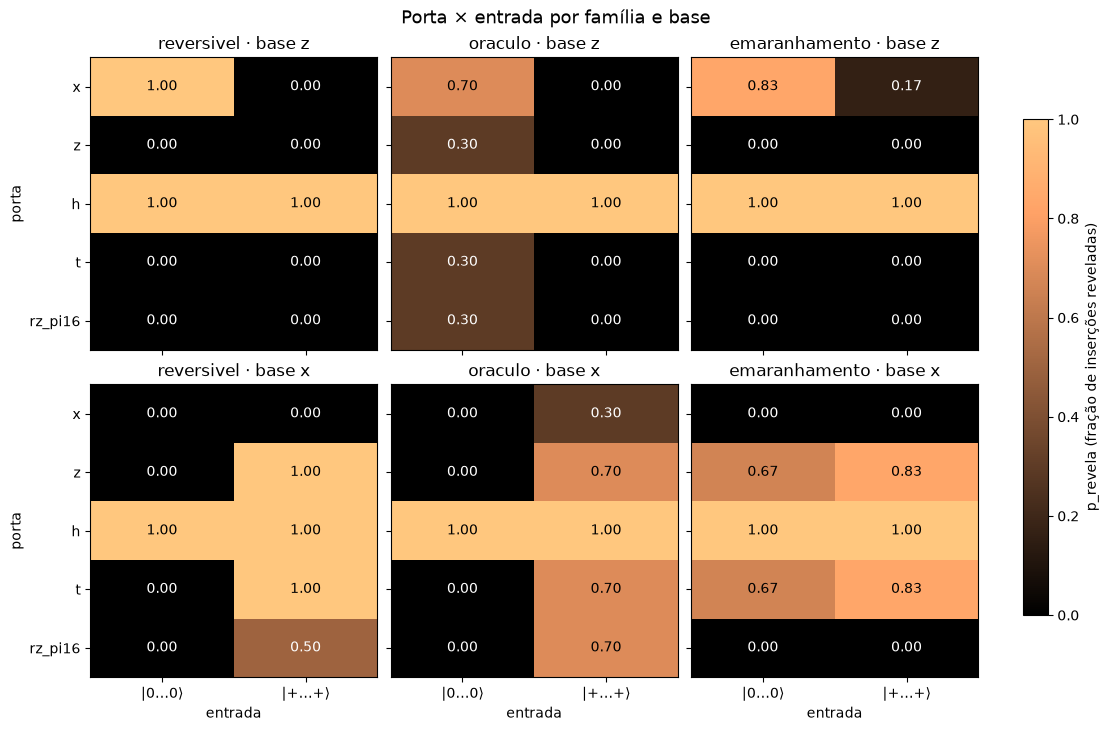

In [6]:
p_med = (longo.groupby(["familia", "base", "porta", "entrada"])["p_revela"]
              .mean())

fig, axes = plt.subplots(
    len(BASES), len(FAMILIAS), figsize=(11, 7.2), sharex=True, sharey=True,
    constrained_layout=True,
)

for i, base in enumerate(BASES):
    for j, fam in enumerate(FAMILIAS):
        ax = axes[i, j]
        mat = (p_med.loc[fam, base]
                    .unstack("entrada")
                    .reindex(index=PORTAS, columns=ENTRADAS))
        im = ax.imshow(mat.values, vmin=0, vmax=1, cmap="copper", aspect="auto")
        for (r, c), v in np.ndenumerate(mat.values):
            ax.text(c, r, f"{v:.2f}", ha="center", va="center",
                    color="white" if v < 0.6 else "black", fontsize=10)
        ax.set_xticks(range(len(ENTRADAS)))
        ax.set_xticklabels([ROTULO_ENTRADA[e] for e in ENTRADAS])
        ax.set_yticks(range(len(PORTAS)))
        ax.set_yticklabels(PORTAS)
        ax.set_title(f"{fam} · base {base}")
        if j == 0:
            ax.set_ylabel("porta")
        if i == len(BASES) - 1:
            ax.set_xlabel("entrada")

fig.colorbar(im, ax=axes, shrink=0.8, label="p_revela (fração de inserções reveladas)")
fig.suptitle("Porta × entrada por família e base", fontsize=13)
plt.show()

## Tabela de k95

`k95` calculado a partir de `p_revela` agregado (média por família, base, porta e entrada). `∞` = a porta nunca é revelada naquela configuração.

In [7]:
p_tab = (p_med.unstack(["base", "entrada"])
              .reindex(index=pd.MultiIndex.from_product([FAMILIAS, PORTAS],
                                                        names=["familia", "porta"]),
                       columns=pd.MultiIndex.from_product([BASES, ENTRADAS],
                                                          names=["base", "entrada"])))

k_tab = p_tab.apply(lambda col: pd.Series(k95(col.values), index=col.index))

def fmt(v):
    return "∞" if np.isinf(v) else f"{int(v)}"

k_txt = k_tab.map(fmt) if hasattr(k_tab, "map") else k_tab.applymap(fmt)
k_txt.columns = pd.MultiIndex.from_tuples(
    [(b, ROTULO_ENTRADA[e]) for b, e in k_txt.columns], names=["base", "entrada"]
)
k_txt

base                      z           x      
entrada               |0…0⟩ |+…+⟩ |0…0⟩ |+…+⟩
familia       porta                          
reversivel    x           1     ∞     ∞     ∞
              z           ∞     ∞     ∞     1
              h           1     1     1     1
              t           ∞     ∞     ∞     1
              rz_pi16     ∞     ∞     ∞     5
oraculo       x           3     ∞     ∞     9
              z           9     ∞     ∞     3
              h           1     1     1     1
              t           9     ∞     ∞     3
              rz_pi16     9     ∞     ∞     3
emaranhamento x           2    17     ∞     ∞
              z           ∞     ∞     3     2
              h           1     1     1     1
              t           ∞     ∞     3     2
              rz_pi16     ∞     ∞     ∞     ∞

Para referência, o `p_revela` agregado que gera a tabela acima:

In [8]:
p_ref = p_tab.round(2)
p_ref.columns = pd.MultiIndex.from_tuples(
    [(b, ROTULO_ENTRADA[e]) for b, e in p_ref.columns], names=["base", "entrada"]
)
p_ref

base                      z           x      
entrada               |0…0⟩ |+…+⟩ |0…0⟩ |+…+⟩
familia       porta                          
reversivel    x        1.00  0.00  0.00  0.00
              z        0.00  0.00  0.00  1.00
              h        1.00  1.00  1.00  1.00
              t        0.00  0.00  0.00  1.00
              rz_pi16  0.00  0.00  0.00  0.50
oraculo       x        0.70  0.00  0.00  0.30
              z        0.30  0.00  0.00  0.70
              h        1.00  1.00  1.00  1.00
              t        0.30  0.00  0.00  0.70
              rz_pi16  0.30  0.00  0.00  0.70
emaranhamento x        0.83  0.17  0.00  0.00
              z        0.00  0.00  0.67  0.83
              h        1.00  1.00  1.00  1.00
              t        0.00  0.00  0.67  0.83
              rz_pi16  0.00  0.00  0.00  0.00